# 06 – Class imbalance and decision threshold

**ML Project – Early Detection of Students at Risk of Dropout** · Week 3

Module owner: **Adam Gaabi** · Group **AALT** (DIA4): Léo Chen, Adam Gaabi, Timéo Brajon, Axel Warot

In [1]:
import sys,json,time,warnings
warnings.filterwarnings("ignore")
sys.path.insert(0,"../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from features import *
from evaluation import *
pd.set_option("display.width",160)
pd.set_option("display.max_columns",40)
tr=pd.read_csv("../data/processed/train.csv")
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from lightgbm import LGBMClassifier
s="B_semester1"
X,y=split_xy(tr,s)
y=encode(y)
p=json.load(open("../results/best_params.json"))["LightGBM"]
p.pop("class_weight",None)
lgbm=lambda cw=None:LGBMClassifier(**p,class_weight=cw,random_state=SEED,n_jobs=1,verbose=-1)
lr=lambda cw=None:LogisticRegression(max_iter=3000,class_weight=cw)
print(p)

{'colsample_bytree': 0.6061695553391381, 'learning_rate': 0.017240892195821537, 'min_child_samples': 30, 'n_estimators': 260, 'num_leaves': 19, 'reg_lambda': 0.27964859516062457, 'subsample': 0.6028265220878869, 'subsample_freq': 1}


## 1. Imbalance strategies
Compared for logistic regression and LightGBM, on the same outer folds:
- **none**, **class weights** (`balanced`),
- **SMOTE** (synthetic minority samples) and **random undersampling**.

Resampling is inside an `imblearn` pipeline: it is applied to the training folds only, the validation fold keeps the real class distribution.

In [2]:
res=[]
for mname,make_m in [("LogReg",lr),("LightGBM",lgbm)]:
    for strat in ["none","class weights","SMOTE","undersampling"]:
        steps=[("prep",preprocessor(s))]
        if strat=="SMOTE":steps.append(("res",SMOTE(random_state=SEED)))
        if strat=="undersampling":steps.append(("res",RandomUnderSampler(random_state=SEED)))
        steps.append(("clf",make_m("balanced" if strat=="class weights" else None)))
        res.append(run_folds(sk(ImbPipeline(steps)),X,y,f"{mname} + {strat}",s))
res=pd.concat(res)
summary(res,("macro_f1","bal_acc","accuracy","dropout_recall","enrolled_f1")).round(3)

macro_f1  macro_f1_std  bal_acc  accuracy  dropout_recall  enrolled_f1
scenario    model                                                                                           
B_semester1 LightGBM + class weights     0.703         0.028    0.709     0.744           0.712        0.519
            LightGBM + undersampling     0.687         0.020    0.699     0.723           0.687        0.499
            LogReg + class weights       0.684         0.022    0.692     0.725           0.699        0.488
            LightGBM + SMOTE             0.679         0.026    0.673     0.749           0.748        0.435
            LogReg + undersampling       0.677         0.021    0.686     0.716           0.687        0.482
            LogReg + SMOTE               0.669         0.020    0.676     0.712           0.702        0.464
            LogReg + none                0.669         0.017    0.661     0.753           0.751        0.401
            LightGBM + none              0.669         0.027    0.661     0.754           0.761        0.393

- Without correction, both models neglect *Enrolled* (F1 ≈ 0.40): all three strategies raise its F1 and the balanced accuracy.
- **Class weights** are the best strategy for both models (LightGBM 0.703, LogReg 0.684), clearly above SMOTE (0.679 / 0.669), and they create no synthetic students: we keep them.
- Undersampling keeps only 635 students per class (it drops 64% of the Graduates) and stays below class weights.

## 2. Decision threshold for dropout
Objective (week 1): flag **at least 80% of the future dropouts**. Rule: predict *Dropout* if P(Dropout) ≥ t, otherwise the most probable of the two other classes.

Without leakage: in each outer training fold, t is chosen on **inner out-of-fold probabilities** (largest t that reaches recall ≥ 0.80), then applied once to the outer fold.

In [3]:
def with_threshold(est,target=0.80):
    def fit_predict(X_tr,y_tr,X_va):
        oof=cross_val_predict(est,X_tr,y_tr,cv=INNER,method="predict_proba")
        ts=np.linspace(0.05,0.95,91)
        ok=[t for t in ts if ((oof[:,DROPOUT]>=t)&(y_tr==DROPOUT)).sum()/(y_tr==DROPOUT).sum()>=target]
        t=max(ok)
        m=est.fit(X_tr,y_tr)
        pr=m.predict_proba(X_va)
        thresholds.append(t)
        return threshold_predict(pr,t),pr
    return fit_predict
rows=[]
for name,est in [("LogReg + weights",Pipeline([("prep",preprocessor(s)),("clf",lr("balanced"))])),("LightGBM + weights",Pipeline([("prep",preprocessor(s)),("clf",lgbm("balanced"))]))]:
    thresholds=[]
    d=run_folds(sk(est),X,y,name+" (argmax)",s)
    t=run_folds(with_threshold(est),X,y,name+" (threshold)",s)
    t["threshold"]=thresholds
    rows+=[d,t]
thr=pd.concat(rows)
thr.to_csv("../results/w3_06_threshold_folds.csv",index=False)
pd.concat([res,thr]).to_csv("../results/w3_06_imbalance_folds.csv",index=False)
summary(thr,("macro_f1","dropout_recall","enrolled_f1","bal_acc")).join(thr.groupby("model")["threshold"].mean().rename("mean t"),on="model").join(thr.groupby("model")["dropout_precision"].mean(),on="model").round(3)

macro_f1  macro_f1_std  dropout_recall  enrolled_f1  bal_acc  mean t  dropout_precision
scenario    model                                                                                                                  
B_semester1 LightGBM + weights (argmax)        0.703         0.028           0.712        0.519    0.709     NaN              0.823
            LogReg + weights (argmax)          0.684         0.022           0.699        0.488    0.692     NaN              0.809
            LightGBM + weights (threshold)     0.671         0.029           0.804        0.439    0.675   0.282              0.714
            LogReg + weights (threshold)       0.664         0.020           0.820        0.432    0.670   0.276              0.701

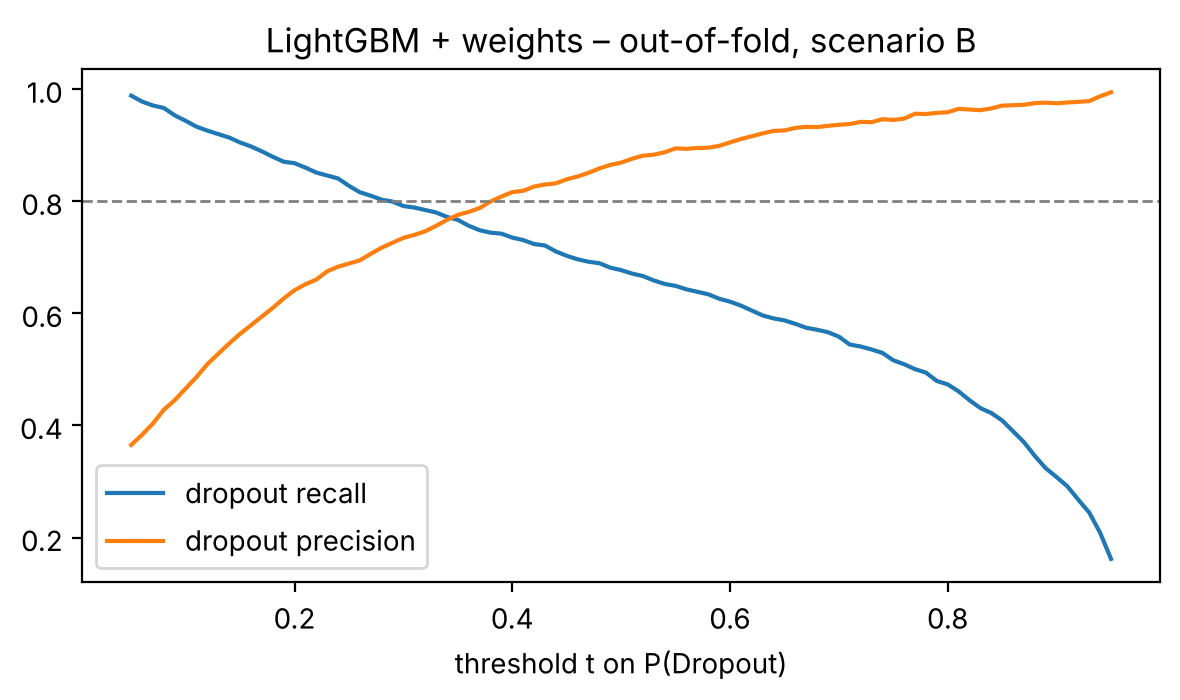

In [4]:
est=Pipeline([("prep",preprocessor(s)),("clf",lgbm("balanced"))])
oof=cross_val_predict(est,X,y,cv=OUTER,method="predict_proba")
ts=np.linspace(0.05,0.95,91)
rec=[((oof[:,DROPOUT]>=t)&(y==DROPOUT)).sum()/(y==DROPOUT).sum() for t in ts]
pre=[((oof[:,DROPOUT]>=t)&(y==DROPOUT)).sum()/max((oof[:,DROPOUT]>=t).sum(),1) for t in ts]
fig,ax=plt.subplots(figsize=(6,3.6))
ax.plot(ts,rec,label="dropout recall");ax.plot(ts,pre,label="dropout precision")
ax.axhline(0.8,ls="--",c="gray",lw=1);ax.set_xlabel("threshold t on P(Dropout)");ax.legend();ax.set_title("LightGBM + weights – out-of-fold, scenario B")
plt.tight_layout();plt.savefig("../report/figures/w3_threshold.png",dpi=150);plt.show()

- With the tuned threshold (t ≈ 0.28) the dropout recall reaches the target: **0.804** for LightGBM and 0.820 for LogReg (vs. 0.71 and 0.70 with argmax). The cost: dropout precision falls from 0.82 to 0.71 and macro-F1 from 0.703 to 0.671 (Enrolled students are now more often flagged as dropouts).
- This is a business choice: the school accepts more false alarms (students offered support who would not have dropped out) to miss fewer real dropouts.
- The threshold is chosen inside each training fold, so the reported recall is not optimistic.